# 함정 8. PTQ와 QAT, 그리고 단계별 QAT와 KD

시드 0·1·2별 float 200 epoch와 그 체크포인트에서 시작한 QAT 20 epoch를 비교한다. PTQ는 증강 없는 학습 이미지로 보정한다. 수치는 완료된 세 시드의 `metrics.json`을 결과 수집 스크립트로 모은다. APoT 크기 4-bit+부호는 31레벨이므로 균일 5-bit 대조군과 비교한다.

스케줄은 즉시 (0,0), 기본 (0.05,0.10), 지연 (0.10,0.20)의 가중치·활성화 시작 비율을 비교한다. BN·observer 동결 비율과 학습 예산은 유지한다. [학습 가이드](../docs/README.md#함정-8-ptq와-qat-그리고-단계별-qat와-kd).

In [1]:
import json
import os
import platform
import time
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'pyproject.toml').exists() else Path.cwd().parent
RESULTS = ROOT / 'runs' / 'm3'
FIGURES = ROOT / 'docs' / 'figures'
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(RESULTS / '.matplotlib'))
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display, Markdown
plt.rcParams.update({'font.family':'DejaVu Sans','svg.fonttype':'none','svg.hashsalt':'quant-pitfalls'})
STARTED = time.perf_counter()
RUN_INFO = {'seeds':[0,1,2], 'python':platform.python_version(), 'torch':torch.__version__,
            'gpu':torch.cuda.get_device_name() if torch.cuda.is_available() else None, 'runtime_seconds':None}
INFO_HANDLE = display(RUN_INFO, display_id=True)
from quant_pitfalls.results import load_results
REPORT, DATA_SOURCE = load_results(ROOT, 'm3')
print('Training numerical input:', DATA_SOURCE)
print('Recorded training environment:', REPORT.get('reports', {}).get('float-baseline-s0', {}).get('environment'))
READY = REPORT.get('state') == 'complete'
if not READY:
    print('Selected training measurements are incomplete; plots are omitted.')

def save_figure(fig, name):
    fig.savefig(FIGURES / (name + '.svg'), bbox_inches='tight', metadata={'Date':None})
    fig.savefig(RESULTS / (name + '.png'), bbox_inches='tight', dpi=140)
    plt.show()

{'seeds': [0, 1, 2],
 'python': '3.11.15',
 'torch': '2.14.1+cu130',
 'gpu': 'NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU',
 'runtime_seconds': 1.334,
 'training_status': 'complete'}

Training numerical input: docs/results/m3.json.gz
Recorded training environment: {'torch': '2.14.1+cu130', 'gpu': 'NVIDIA GeForce RTX 5090'}


| 설정 | 가중치 | 활성화 | top-1 (%) | float 대비 |
|---|---|---|---|---|
| float | FP32 | FP32 | 92.40 ± 0.12 (n=3) | — |
| PTQ, per-tensor | 8 | 8 | 91.57 ± 0.50 (n=3) | -0.83 pp |
| PTQ, per-channel | 8 | 8 | 92.27 ± 0.13 (n=3) | -0.13 pp |
| PTQ, per-channel, min/max 클립 | 4 | 8 | 88.80 ± 0.58 (n=3) | -3.61 pp |
| PTQ, per-channel, MSE 클립 | 4 | 8 | 88.02 ± 0.80 (n=3) | -4.38 pp |
| QAT, 한 번에 | 4 | 8 | 92.07 ± 0.03 (n=3) | -0.33 pp |
| QAT, 단계별 | 4 | 8 | 92.22 ± 0.07 (n=3) | -0.19 pp |
| QAT, 단계별 + KD | 4 | 8 | 92.28 ± 0.21 (n=3) | -0.12 pp |
| QAT, 단계별, APoT 가중치 | 4 + sign | 8 | 92.21 ± 0.28 (n=3) | -0.19 pp |
| QAT, 단계별, 균일 31레벨 (APoT 대조군) | 5 | 8 | 92.13 ± 0.15 (n=3) | -0.27 pp |
| QAT, 단계별, floor 활성화 | 4 | 8 | 92.03 ± 0.07 (n=3) | -0.38 pp |

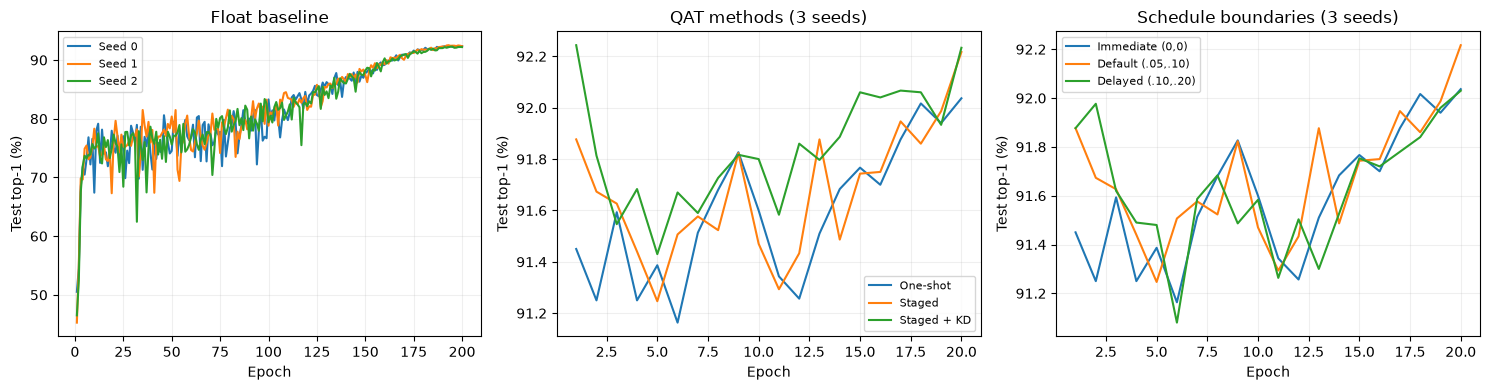

In [2]:
import sys
sys.path.insert(0, str(ROOT / 'scripts'))
from collect_results import collect_reports
result_table, result_values = collect_reports(REPORT.get('reports', {}))
display(Markdown(result_table))
if READY:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for seed in (0,1,2):
        run=REPORT['reports'][f'float-baseline-s{seed}']
        axes[0].plot([h['epoch'] for h in run['history']], [h['test_top1'] for h in run['history']],label=f'Seed {seed}')
    for label,prefix in (
        ('One-shot','qat-w4a8-pc-mse-one-shot-uniform-nearest-fp32'),
        ('Staged','qat-w4a8-pc-mse-staged-uniform-nearest-fp32'),
        ('Staged + KD','qat-w4a8-pc-mse-staged-uniform-nearest-fp32-kd')):
        history=[REPORT['reports'][f'{prefix}-s{s}']['history'] for s in (0,1,2)]
        curve=np.array([[h['test_top1'] for h in items] for items in history])
        axes[1].plot(np.arange(1,21),curve.mean(0),label=label)
    for label,prefix in (
        ('Immediate (0,0)','qat-w4a8-pc-mse-one-shot-uniform-nearest-fp32'),
        ('Default (.05,.10)','qat-w4a8-pc-mse-staged-uniform-nearest-fp32'),
        ('Delayed (.10,.20)','nb08-delayed')):
        history=[REPORT['reports'][f'{prefix}-s{s}']['history'] for s in (0,1,2)]
        curve=np.array([[h['test_top1'] for h in items] for items in history])
        axes[2].plot(np.arange(1,21),curve.mean(0),label=label)
    for ax,title in zip(axes,('Float baseline','QAT methods (3 seeds)','Schedule boundaries (3 seeds)')):
        ax.set_title(title)
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Test top-1 (%)')
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    fig.tight_layout()
    save_figure(fig,'08_ptq-vs-qat')

In [3]:
RUN_INFO['runtime_seconds'] = round(time.perf_counter()-STARTED, 3)
RUN_INFO['training_status'] = REPORT['state']
INFO_HANDLE.update(RUN_INFO)

## 직접 확인하기

같은 시드의 float와 단계별 W4A8 QAT 결과를 짝지어 정확도 차이를 계산해 보자. 세 시드 평균과 표본 표준편차가 전체 표와 일치하는지 확인하자.
